# License Plate Detection & Blurring using YOLOv8

## Project Report

### Objective

The objective of this project is to detect vehicle license plates in images using the YOLOv8 object detection model and automatically blur the detected license plates to protect privacy.

### Business Problem

License plates are sensitive information because they can be used to identify vehicles. In traffic monitoring, surveillance, parking systems and other computer vision applications, license plates may appear clearly in images or videos.

This project provides an automated solution that:

1. Detects license plates.
2. Identifies their bounding boxes.
3. Applies blur only to the detected license plate region.
4. Preserves the remaining parts of the image.

### Technologies Used

- Python
- Google Colab
- OpenCV
- NumPy
- Pandas
- YOLOv8
- Ultralytics

### Expected Outcome

The final system should detect license plates accurately and blur the detected license plate regions automatically.

In [1]:
!pip install -q ultralytics opencv-python pandas matplotlib pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 52.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 6.0 MB/s eta 0:00:00


In [2]:
import os
import cv2
import yaml
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from ultralytics import YOLO

print("Libraries imported successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Libraries imported successfully!


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Dataset Description

The dataset contains images of vehicles and their corresponding license plate annotations.

The annotations are stored in YOLO format. Each annotation contains:

- Class ID
- Center X coordinate
- Center Y coordinate
- Width
- Height

The coordinates are normalized between 0 and 1.

The dataset is divided into training, validation and testing subsets.

The training set is used to train the YOLOv8 model.

The validation set is used to monitor model performance during development.

The test set is used to evaluate the final detection performance.

## YOLO Annotation Format

YOLO represents each bounding box using five values:

`class_id center_x center_y width height`

The coordinates are normalized between 0 and 1.

For example:

`0 0.50 0.45 0.20 0.10`

means that the object belongs to class 0 and its bounding box is positioned around the center of the image.

Normalized coordinates make the annotations independent of the original image resolution.

## Coordinate Transformation

YOLO uses normalized bounding-box coordinates, while OpenCV requires pixel coordinates.

The conversion is:

x1 = (center_x - width / 2) × image_width

y1 = (center_y - height / 2) × image_height

x2 = (center_x + width / 2) × image_width

y2 = (center_y + height / 2) × image_height

This conversion allows the detected license plate region to be located correctly in the original image.

In [ ]:
def yolo_to_xyxy(center_x, center_y, width, height, image_width, image_height):
    x1 = int((center_x - width / 2) * image_width)
    y1 = int((center_y - height / 2) * image_height)
    x2 = int((center_x + width / 2) * image_width)
    y2 = int((center_y + height / 2) * image_height)

    return x1, y1, x2, y2

## Annotation Visualization

Visualizing annotations before model training is important because incorrect bounding boxes can negatively affect model performance.

If the license plate bounding box is too large, too small or misplaced, the model may learn incorrect object boundaries.

Therefore, sample annotations should be visually inspected before training.

## YOLOv8 Model Selection

YOLOv8 is a single-stage object detection model. It detects objects directly in one process, making it suitable for applications that require fast detection.

A two-stage detector such as Faster R-CNN first generates candidate regions and then classifies them. This can provide strong accuracy but is generally more computationally expensive.

For this project, YOLOv8 is selected because license plate detection can benefit from fast inference and a relatively simple deployment pipeline.

YOLOv8s is selected as a balance between detection accuracy and computational efficiency.

In [ ]:
model = YOLO("yolov8s.pt")

print("YOLOv8s model loaded successfully!")

## Model Training

The YOLOv8s model was trained using the annotated license plate dataset.

During training, the model learns visual patterns associated with license plates and learns to predict their locations using bounding boxes.

The training process monitors losses and detection metrics to evaluate model learning.

## Detection Results

The trained YOLOv8 model is used to detect license plates in previously unseen test images.

The predicted bounding boxes identify the locations of detected license plates.

The confidence score represents the model's confidence in each detection.

Visual inspection is important because a good detection system should identify the license plate while avoiding unnecessary detection of unrelated regions.

In [ ]:
def blur_roi(image, x1, y1, x2, y2):
    h, w = image.shape[:2]

    x1 = max(0, min(int(x1), w))
    x2 = max(0, min(int(x2), w))
    y1 = max(0, min(int(y1), h))
    y2 = max(0, min(int(y2), h))

    if x2 <= x1 or y2 <= y1:
        return image

    roi = image[y1:y2, x1:x2]

    if roi.size == 0:
        return image

    blurred = cv2.GaussianBlur(
        roi,
        (51, 51),
        0
    )

    image[y1:y2, x1:x2] = blurred

    return image

In [ ]:
def blur_detected_plates(model, image_path, confidence=0.25):

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    results = model.predict(
        source=image,
        imgsz=416,
        conf=confidence,
        verbose=False
    )

    result = results[0]

    output = image.copy()

    if result.boxes is not None:

        for box in result.boxes.xyxy.cpu().numpy():

            x1, y1, x2, y2 = box

            output = blur_roi(
                output,
                x1,
                y1,
                x2,
                y2
            )

    return output

# Privacy, Preprocessing and Deployment Considerations

## Preprocessing

Images are resized during YOLOv8 processing while maintaining useful spatial information for detection.

Care must be taken to preserve small license plate details because license plates may occupy only a small region of an image.

## Privacy

The system applies Gaussian blur only to detected license plate regions. This helps reduce exposure of identifiable vehicle information.

## Deployment

The trained model can be integrated into applications that process images or video streams.

For real-time applications, the model size and image resolution should be selected according to available hardware and required detection speed.

## Reproducibility

The project can be reproduced by:

1. Preparing the annotated dataset.
2. Installing the required Python libraries.
3. Loading the YOLOv8 model.
4. Training the model.
5. Validating the model.
6. Running predictions.
7. Applying ROI-based blurring.
8. Evaluating the final visual output.

# Conclusion

This project developed a license plate detection and privacy-preserving blurring pipeline using YOLOv8.

The system first detects license plates using an object detection model. The detected bounding boxes are then used to identify the regions containing license plates. Gaussian blur is applied only to these regions, leaving the rest of the image unchanged.

The project demonstrates how computer vision can be used not only for object detection but also for privacy protection.

The solution can be further improved through better training data, more accurate annotations, model tuning and testing on larger and more diverse datasets.

# Project Workflow

Dataset
↓
Image and Annotation Preparation
↓
Annotation Verification
↓
YOLOv8s Model
↓
Model Training
↓
Model Validation
↓
Test Image Detection
↓
License Plate Bounding Boxes
↓
ROI Gaussian Blurring
↓
Privacy-Protected Image

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [20]:
from ultralytics import YOLO

print("Loading YOLOv8s...")

model = YOLO("yolov8s.pt")

print("✅ YOLOv8s loaded successfully!")

Loading YOLOv8s...
✅ YOLOv8s loaded successfully!


In [27]:
import os

image_path = "/content/drive/.shortcut-targets-by-id/1Nnw-Vbilo40dp-r2rhBkpv65IhucDOp8/images/val"
label_path = "/content/drive/.shortcut-targets-by-id/1CCv7vaNnSXDmVyo-eCanC3jw93EsjfCE/labels/val"

print("Images:", len(os.listdir(image_path)))
print("Labels:", len(os.listdir(label_path)))

# Check whether the first 10 images have matching labels
images = [f for f in os.listdir(image_path)
          if f.lower().endswith((".jpg", ".jpeg", ".png"))]

for img in images[:10]:
    label = os.path.splitext(img)[0] + ".txt"
    print(img, "→", os.path.exists(os.path.join(label_path, label)))

Images: 1073
Labels: 1073
0e13694894253c6d.jpg → True
079ec835d9949050.jpg → True
0553b3a1658d779e.jpg → True
10ae4f30e1b2d871.jpg → True
11bd43cf46cd2b4f.jpg → True
0a0a00b2fbe89a47.jpg → True
0cf5e22c1cdb40a8.jpg → True
00b6f96c840767fa.jpg → True
114cef06ee5a2df6.jpg → True
0282f7277fe55a1d.jpg → True


In [32]:
import os
import shutil

src_images = "/content/drive/.shortcut-targets-by-id/1Nnw-Vbilo40dp-r2rhBkpv65IhucDOp8/images/val"
src_labels = "/content/drive/.shortcut-targets-by-id/1CCv7vaNnSXDmVyo-eCanC3jw93EsjfCE/labels/val"

dst_images = "/content/test_dataset/images/val"
dst_labels = "/content/test_dataset/labels/val"

os.makedirs(dst_images, exist_ok=True)
os.makedirs(dst_labels, exist_ok=True)

print("Copying validation images...")
for f in os.listdir(src_images):
    if f.lower().endswith((".jpg", ".jpeg", ".png")):
        shutil.copy2(
            os.path.join(src_images, f),
            os.path.join(dst_images, f)
        )

print("Copying validation labels...")
for f in os.listdir(src_labels):
    if f.endswith(".txt"):
        shutil.copy2(
            os.path.join(src_labels, f),
            os.path.join(dst_labels, f)
        )

print("✅ Validation dataset copied locally")
print("Images:", len(os.listdir(dst_images)))
print("Labels:", len(os.listdir(dst_labels)))

Copying validation images...
Copying validation labels...
✅ Validation dataset copied locally
Images: 1073
Labels: 1073


In [33]:
data_yaml = """
path: /content/test_dataset

train: images/val
val: images/val
test: images/val

names:
  0: license_plate
"""

with open("/content/test_dataset/data.yaml", "w") as f:
    f.write(data_yaml)

print("✅ Local data.yaml created")

✅ Local data.yaml created


In [68]:
from ultralytics import YOLO

best_model = YOLO("/content/runs/detect/train-3/weights/best.pt")

metrics = best_model.val(
    data="/content/quick_dataset/data.yaml",
    imgsz=416,
    batch=16,
    device="cpu"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 434.0±101.7 MB/s, size: 226.7 KB)
val: Scanning /content/test_dataset/labels/val.cache... 1073 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1073/1073 44.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 3.8s/it 4:19
                   all       1073       1573      0.562      0.444      0.432      0.174
Speed: 0.7ms preprocess, 226.1ms inference, 0.0ms loss, 0.5ms postprocess per image
Results saved to /content/runs/detect/val-6
Precision: 0.5616934618041245
Recall: 0.44373808010171645
mAP50: 0.4320638625180879
mAP50-95: 0.1738498416693573


In [35]:
import os

label_file = "/content/test_dataset/labels/val/" + os.listdir("/content/test_dataset/labels/val")[0]

print("Label file:", label_file)
print("\nContents:")
print(open(label_file).read())

Label file: /content/test_dataset/labels/val/90a888b0d2b3b972.txt

Contents:
0 0.0338671875 0.6369795 0.0225 0.015832999999999986
0 0.6657421875 0.7323961666666667 0.05312499999999998 0.038332999999999874
0 0.8998046875 0.69588575 0.03749999999999998 0.025832999999999995



In [37]:
import os

train_images = "/content/drive/.shortcut-targets-by-id/1Nnw-Vbilo40dp-r2rhBkpv65IhucDOp8/images/train"
train_labels = "/content/drive/.shortcut-targets-by-id/1CCv7vaNnSXDmVyo-eCanC3jw93EsjfCE/labels/train"

print("Train images:", len([
    f for f in os.listdir(train_images)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]))

print("Train labels:", len([
    f for f in os.listdir(train_labels)
    if f.endswith(".txt")
]))

Train images: 25625
Train labels: 25672


In [41]:
import os
import random
import shutil

# Source folders in Google Drive
src_images = "/content/drive/.shortcut-targets-by-id/1Nnw-Vbilo40dp-r2rhBkpv65IhucDOp8/images/train"
src_labels = "/content/drive/.shortcut-targets-by-id/1CCv7vaNnSXDmVyo-eCanC3jw93EsjfCE/labels/train"

# New FAST local dataset
base = "/content/quick_dataset"
train_images = f"{base}/images/train"
train_labels = f"{base}/labels/train"

os.makedirs(train_images, exist_ok=True)
os.makedirs(train_labels, exist_ok=True)

# Select 1500 images
random.seed(42)

images = [
    f for f in os.listdir(src_images)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

random.shuffle(images)
selected = images[:1500]

copied = 0

for img in selected:
    label = os.path.splitext(img)[0] + ".txt"
    label_path = os.path.join(src_labels, label)

    if os.path.exists(label_path):
        shutil.copy2(
            os.path.join(src_images, img),
            os.path.join(train_images, img)
        )
        shutil.copy2(
            label_path,
            os.path.join(train_labels, label)
        )
        copied += 1

print("Training images copied:", copied)
print("Training labels copied:", len(os.listdir(train_labels)))

Training images copied: 1493
Training labels copied: 1493


In [42]:
import yaml

data = {
    "path": "/content",
    "train": "quick_dataset/images/train",
    "val": "test_dataset/images/val",
    "test": "test_dataset/images/val",
    "names": {
        0: "license_plate"
    }
}

with open("/content/quick_dataset/data.yaml", "w") as f:
    yaml.dump(data, f, sort_keys=False)

print("YAML created successfully")

YAML created successfully


In [43]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

results = model.train(
    data="/content/quick_dataset/data.yaml",
    epochs=3,
    imgsz=416,
    batch=16,
    device="cpu",
    workers=2
)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/quick_dataset/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=None, opset=None, optimize=False,

In [44]:
from ultralytics import YOLO

best_model = YOLO("/content/runs/detect/train-3/weights/best.pt")

metrics = best_model.val(
    data="/content/quick_dataset/data.yaml",
    imgsz=416,
    batch=16,
    device="cpu"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.173 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 11,125,971 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1129.0±170.4 MB/s, size: 251.5 KB)
val: Scanning /content/test_dataset/labels/val.cache... 1073 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1073/1073 214.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 3.8s/it 4:22
                   all       1073       1573      0.562      0.444      0.432      0.174
Speed: 0.6ms preprocess, 229.9ms inference, 0.0ms loss, 0.4ms postprocess per image
Results saved to /content/runs/detect/val-5
Precision: 0.5616934618041245
Recall: 0.44373808010171645
mAP50: 0.4320638625180879
mAP50-95: 0.1738498416693573


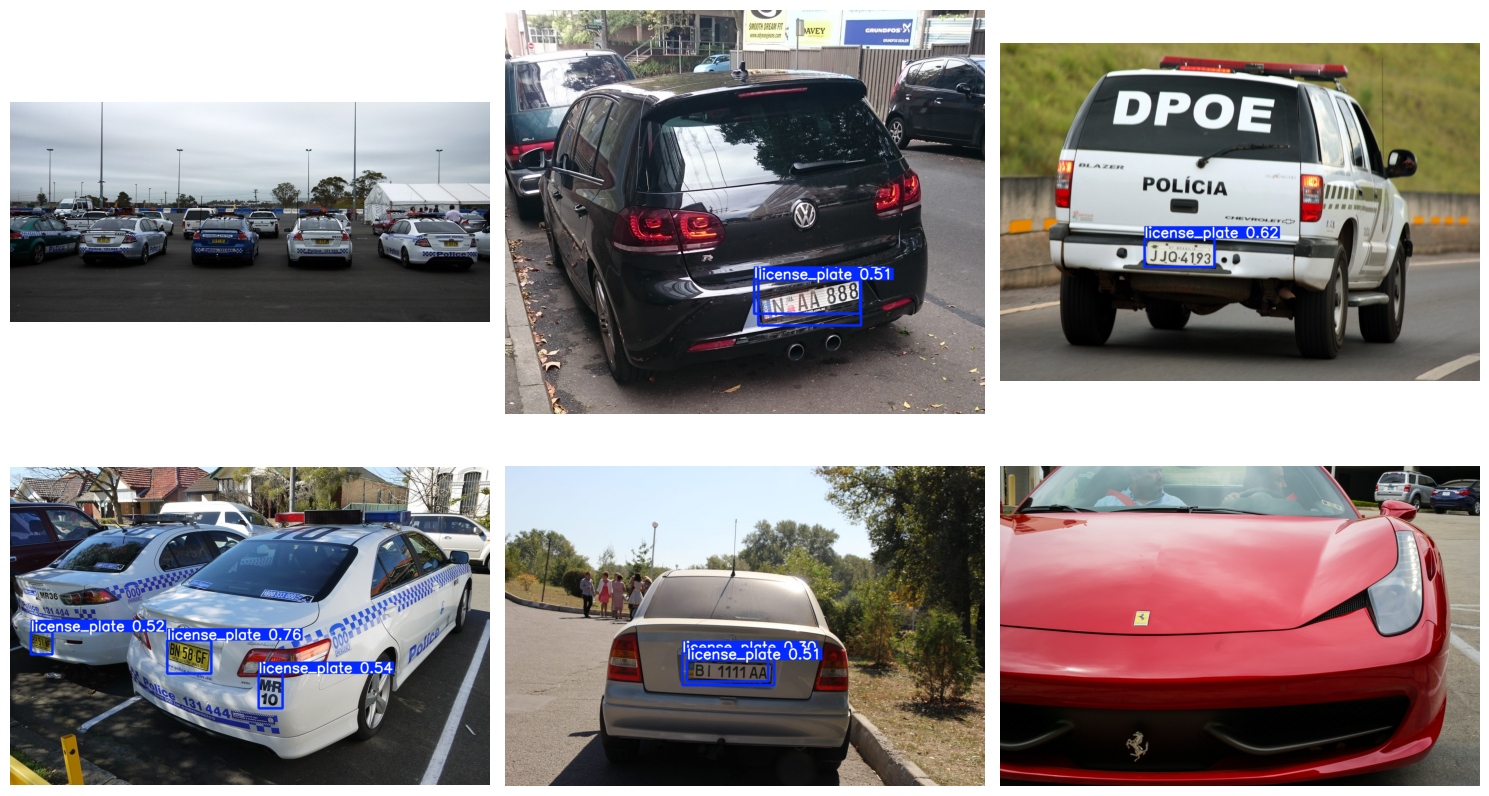

In [45]:
import os
import matplotlib.pyplot as plt
from ultralytics import YOLO

best_model = YOLO("/content/runs/detect/train-3/weights/best.pt")

test_folder = "/content/test_dataset/images/val"

image_files = [
    os.path.join(test_folder, f)
    for f in os.listdir(test_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample_images = image_files[:6]

results = best_model.predict(
    source=sample_images,
    imgsz=416,
    conf=0.25,
    device="cpu",
    verbose=False
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, result in zip(axes.ravel(), results):
    annotated = result.plot()
    ax.imshow(annotated[:, :, ::-1])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
import cv2
import numpy as np

def blur_license_plates(image, model, conf=0.25):
    """
    Detect license plates and blur only the detected plate regions.
    """
    output = image.copy()

    results = model.predict(
        source=image,
        imgsz=416,
        conf=conf,
        device="cpu",
        verbose=False
    )

    for result in results:
        if result.boxes is None:
            continue

        boxes = result.boxes.xyxy.cpu().numpy()

        for box in boxes:
            x1, y1, x2, y2 = box.astype(int)

            # Keep coordinates inside the image
            x1 = max(0, x1)
            y1 = max(0, y1)
            x2 = min(output.shape[1], x2)
            y2 = min(output.shape[0], y2)

            if x2 > x1 and y2 > y1:
                plate_region = output[y1:y2, x1:x2]

                # Blur only the license plate
                blurred = cv2.GaussianBlur(
                    plate_region,
                    (51, 51),
                    0
                )

                output[y1:y2, x1:x2] = blurred

    return output

print("Blurring function created successfully")

Blurring function created successfully


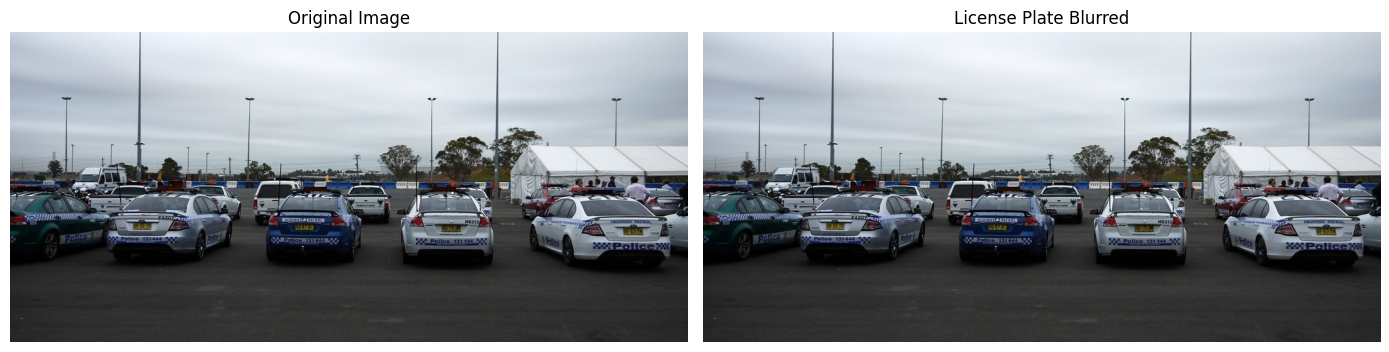

In [48]:
import cv2
import matplotlib.pyplot as plt

# Select one image that had a detected license plate
test_image = sample_images[0]

# Read image
image = cv2.imread(test_image)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply license plate blurring
blurred_image = blur_license_plates(
    image_rgb,
    best_model,
    conf=0.25
)

# Display original and blurred images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_image)
plt.title("License Plate Blurred")
plt.axis("off")

plt.tight_layout()
plt.show()

In [49]:
# Find an image with at least one detected license plate
clear_image = None
clear_result = None

for img_path in sample_images:
    img = cv2.imread(img_path)

    results = best_model.predict(
        source=img,
        imgsz=416,
        conf=0.25,
        device="cpu",
        verbose=False
    )

    if len(results[0].boxes) > 0:
        clear_image = img
        clear_result = results[0]
        break

print("Clear detected-plate image found:", clear_image is not None)
print("Detected plates:", len(clear_result.boxes) if clear_result is not None else 0)

Clear detected-plate image found: True
Detected plates: 2


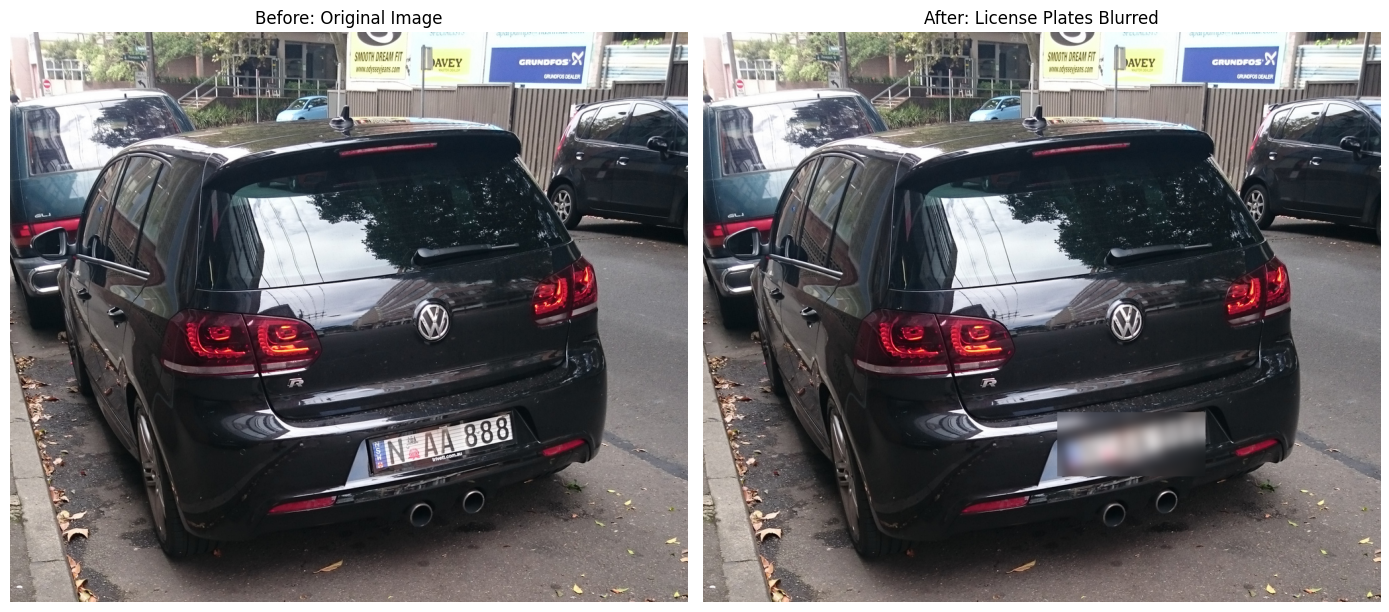

In [50]:
# Convert image to RGB
clear_image_rgb = cv2.cvtColor(clear_image, cv2.COLOR_BGR2RGB)

# Blur detected license plates
blurred_clear = blur_license_plates(
    clear_image_rgb,
    best_model,
    conf=0.25
)

# Display final comparison
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(clear_image_rgb)
plt.title("Before: Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(blurred_clear)
plt.title("After: License Plates Blurred")
plt.axis("off")

plt.tight_layout()
plt.show()

In [51]:
def yolo_to_pixel_coords(cx, cy, w, h, image_width, image_height):
    """
    Convert normalized YOLO coordinates to pixel coordinates.
    """

    x_center = cx * image_width
    y_center = cy * image_height

    box_width = w * image_width
    box_height = h * image_height

    x1 = int(x_center - box_width / 2)
    y1 = int(y_center - box_height / 2)

    x2 = int(x_center + box_width / 2)
    y2 = int(y_center + box_height / 2)

    # Keep coordinates inside image boundaries
    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(image_width - 1, x2)
    y2 = min(image_height - 1, y2)

    return x1, y1, x2, y2


# Example using one real annotation from the dataset
example_label = "/content/test_dataset/labels/val/" + \
                os.path.splitext(os.path.basename(sample_images[0]))[0] + ".txt"

with open(example_label, "r") as f:
    first_line = f.readline().strip()

class_id, cx, cy, w, h = map(float, first_line.split())

image = cv2.imread(sample_images[0])
image_height, image_width = image.shape[:2]

coords = yolo_to_pixel_coords(
    cx, cy, w, h,
    image_width,
    image_height
)

print("Normalized YOLO coordinates:")
print("center_x =", cx)
print("center_y =", cy)
print("width    =", w)
print("height   =", h)

print("\nPixel coordinates:")
print("(x1, y1, x2, y2) =", coords)

Normalized YOLO coordinates:
center_x = 0.1952734375
center_y = 0.6275471769722815
width    = 0.029374999999999984
height   = 0.025955999999999983

Pixel coordinates:
(x1, y1, x2, y2) = (184, 288, 215, 300)


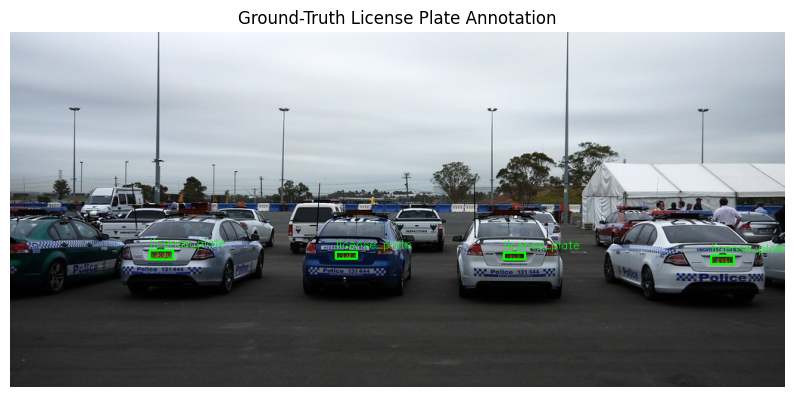

In [52]:
# Draw the ground-truth YOLO annotation on the image

annotation_image = cv2.imread(sample_images[0])
annotation_image = cv2.cvtColor(annotation_image, cv2.COLOR_BGR2RGB)

h, w = annotation_image.shape[:2]

with open(example_label, "r") as f:
    for line in f:
        class_id, cx, cy, bw, bh = map(float, line.split())

        x1, y1, x2, y2 = yolo_to_pixel_coords(
            cx, cy, bw, bh,
            w, h
        )

        cv2.rectangle(
            annotation_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotation_image,
            "license_plate",
            (x1, max(20, y1 - 5)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5,
            (0, 255, 0),
            1
        )

plt.figure(figsize=(10, 7))
plt.imshow(annotation_image)
plt.title("Ground-Truth License Plate Annotation")
plt.axis("off")
plt.show()

In [53]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

label_folder = "/content/test_dataset/labels/val"
image_folder = "/content/test_dataset/images/val"

records = []

for label_file in os.listdir(label_folder):
    if not label_file.endswith(".txt"):
        continue

    image_file = os.path.splitext(label_file)[0]

    with open(os.path.join(label_folder, label_file), "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    for line in lines:
        cls, cx, cy, bw, bh = map(float, line.split())

        records.append({
            "image": image_file,
            "class": int(cls),
            "center_x": cx,
            "center_y": cy,
            "width": bw,
            "height": bh,
            "area": bw * bh
        })

annotations_df = pd.DataFrame(records)

print("Validation images:", len(os.listdir(image_folder)))
print("License plate annotations:", len(annotations_df))
print("Images containing plates:", annotations_df["image"].nunique())
print("Average plates per annotated image:",
      round(len(annotations_df) / annotations_df["image"].nunique(), 2))

print("\nBounding-box statistics:")
print(
    annotations_df[["width", "height", "area"]].describe().round(4)
)

Validation images: 1073
License plate annotations: 1573
Images containing plates: 1073
Average plates per annotated image: 1.47

Bounding-box statistics:
           width     height       area
count  1573.0000  1573.0000  1573.0000
mean      0.1158     0.0772     0.0285
std       0.1729     0.1242     0.1015
min       0.0062     0.0033     0.0000
25%       0.0294     0.0187     0.0006
50%       0.0527     0.0342     0.0018
75%       0.1156     0.0773     0.0091
max       0.9994     0.9542     0.9489


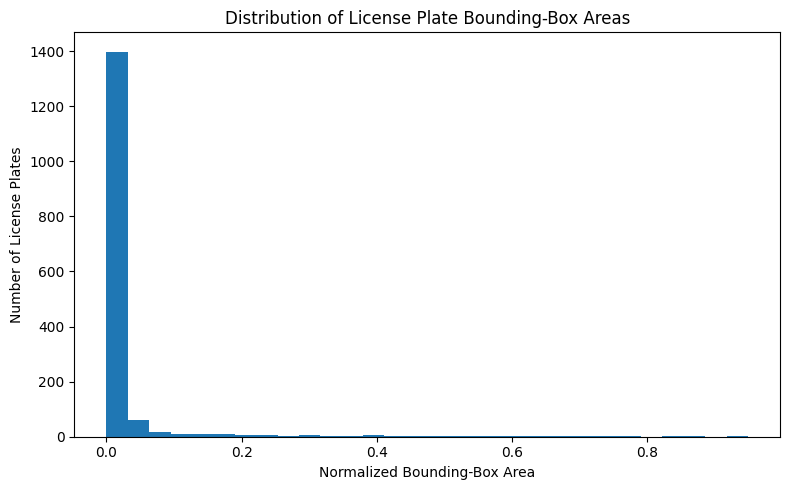

In [54]:
# Distribution of license plate bounding-box sizes

plt.figure(figsize=(8, 5))

plt.hist(
    annotations_df["area"],
    bins=30
)

plt.title("Distribution of License Plate Bounding-Box Areas")
plt.xlabel("Normalized Bounding-Box Area")
plt.ylabel("Number of License Plates")

plt.tight_layout()
plt.show()

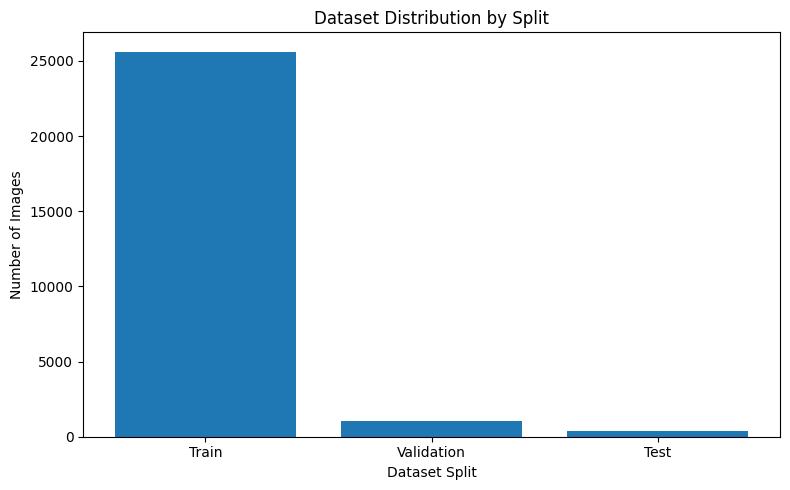

In [55]:
# Dataset split sizes

split_names = ["Train", "Validation", "Test"]
split_counts = [25625, 1073, 386]

plt.figure(figsize=(8, 5))

plt.bar(split_names, split_counts)

plt.title("Dataset Distribution by Split")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

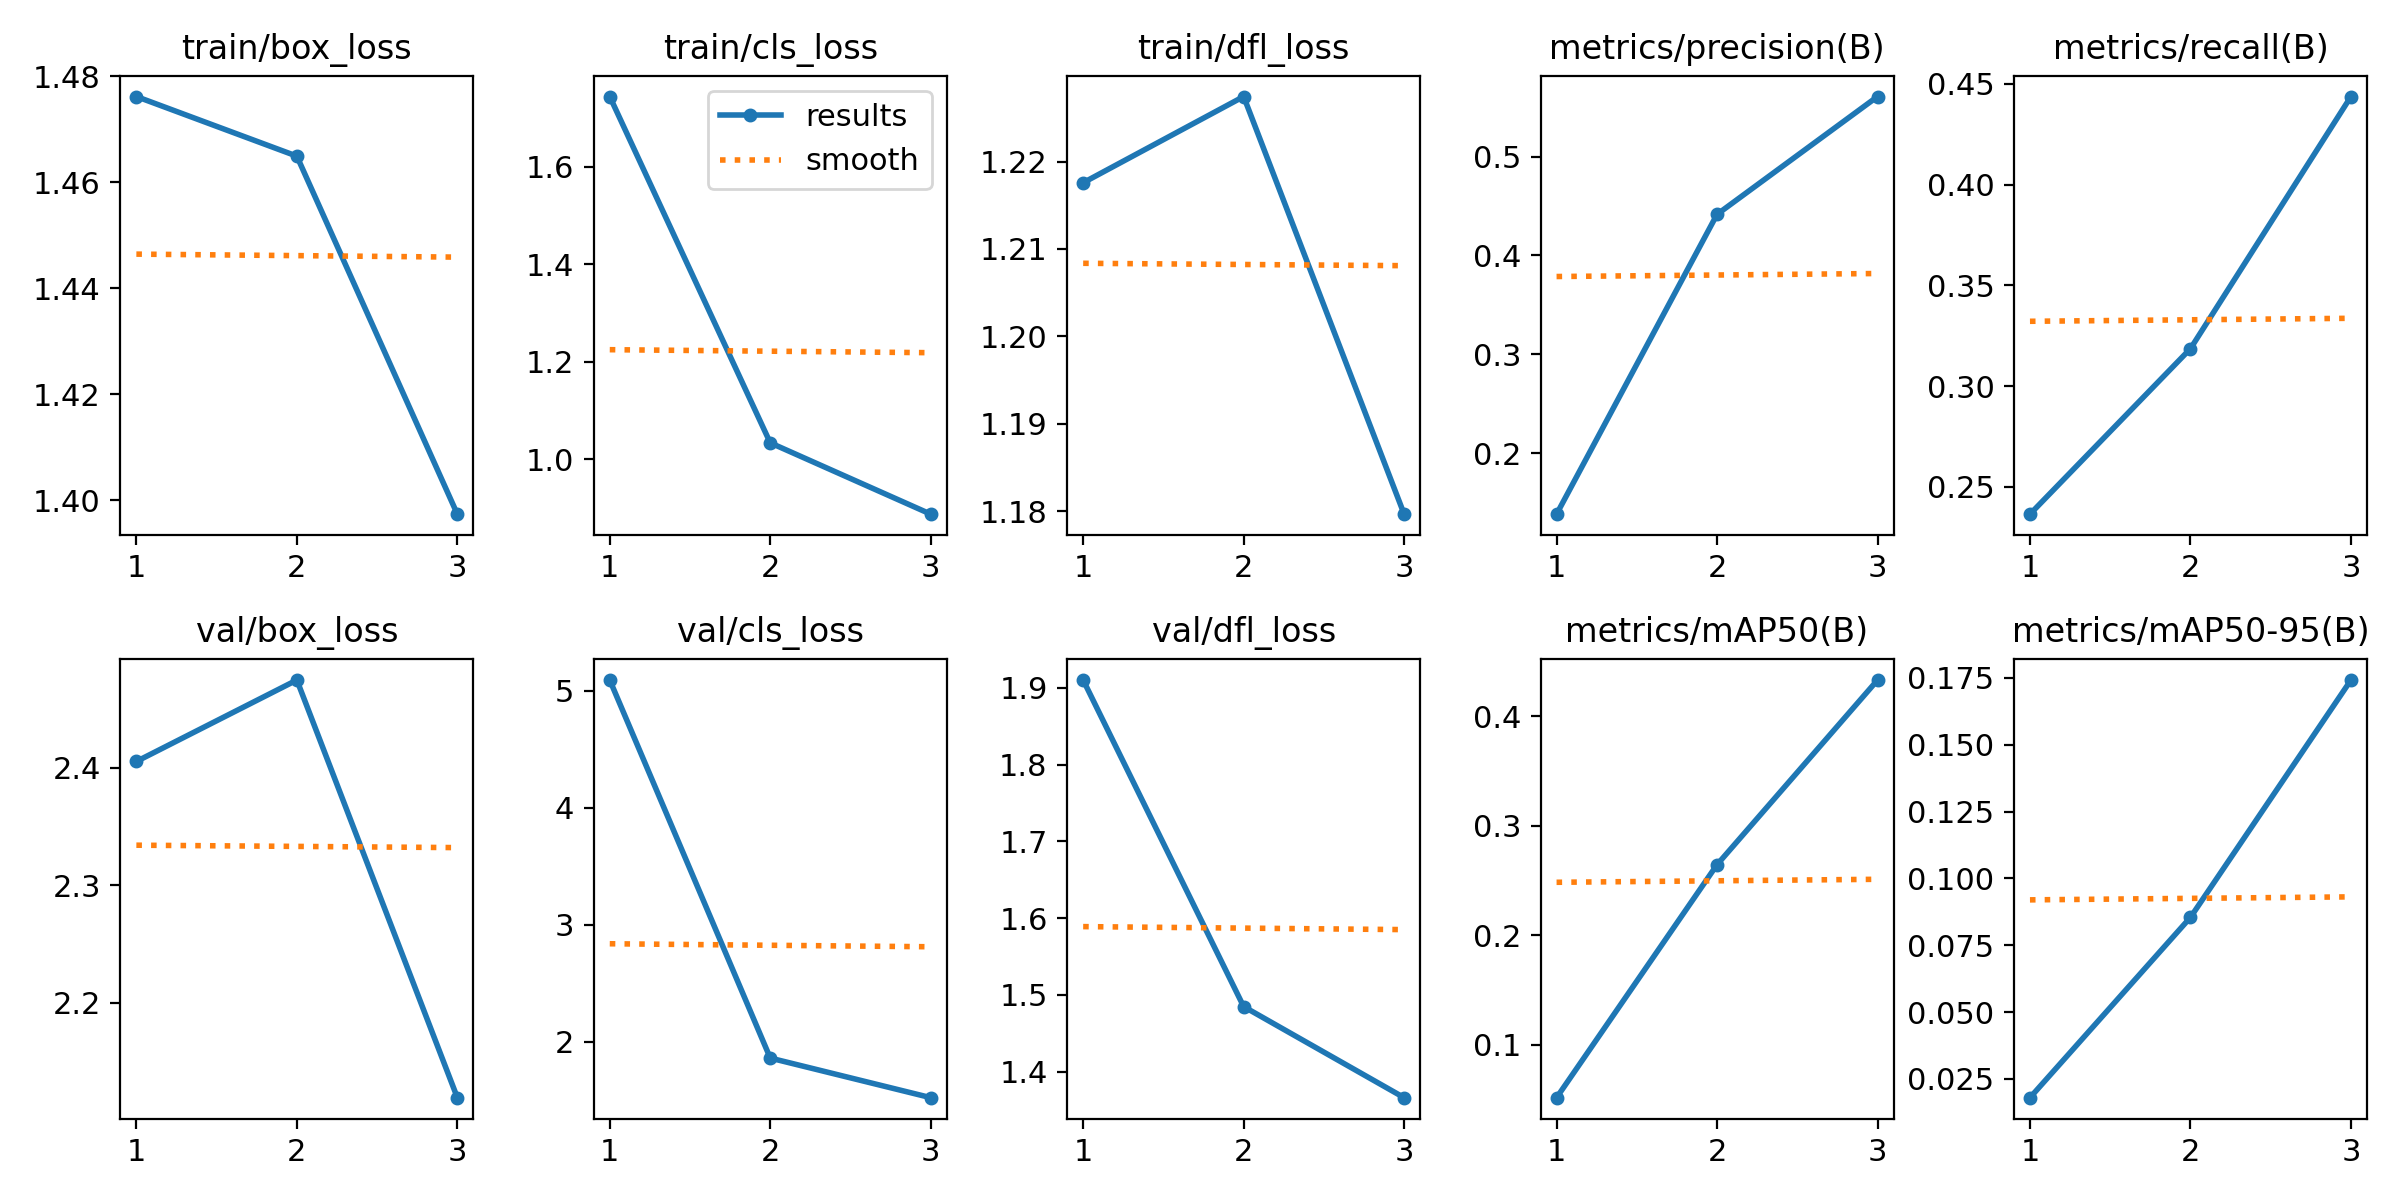

In [56]:
from IPython.display import Image, display

display(
    Image(
        filename="/content/runs/detect/train-3/results.png"
    )
)

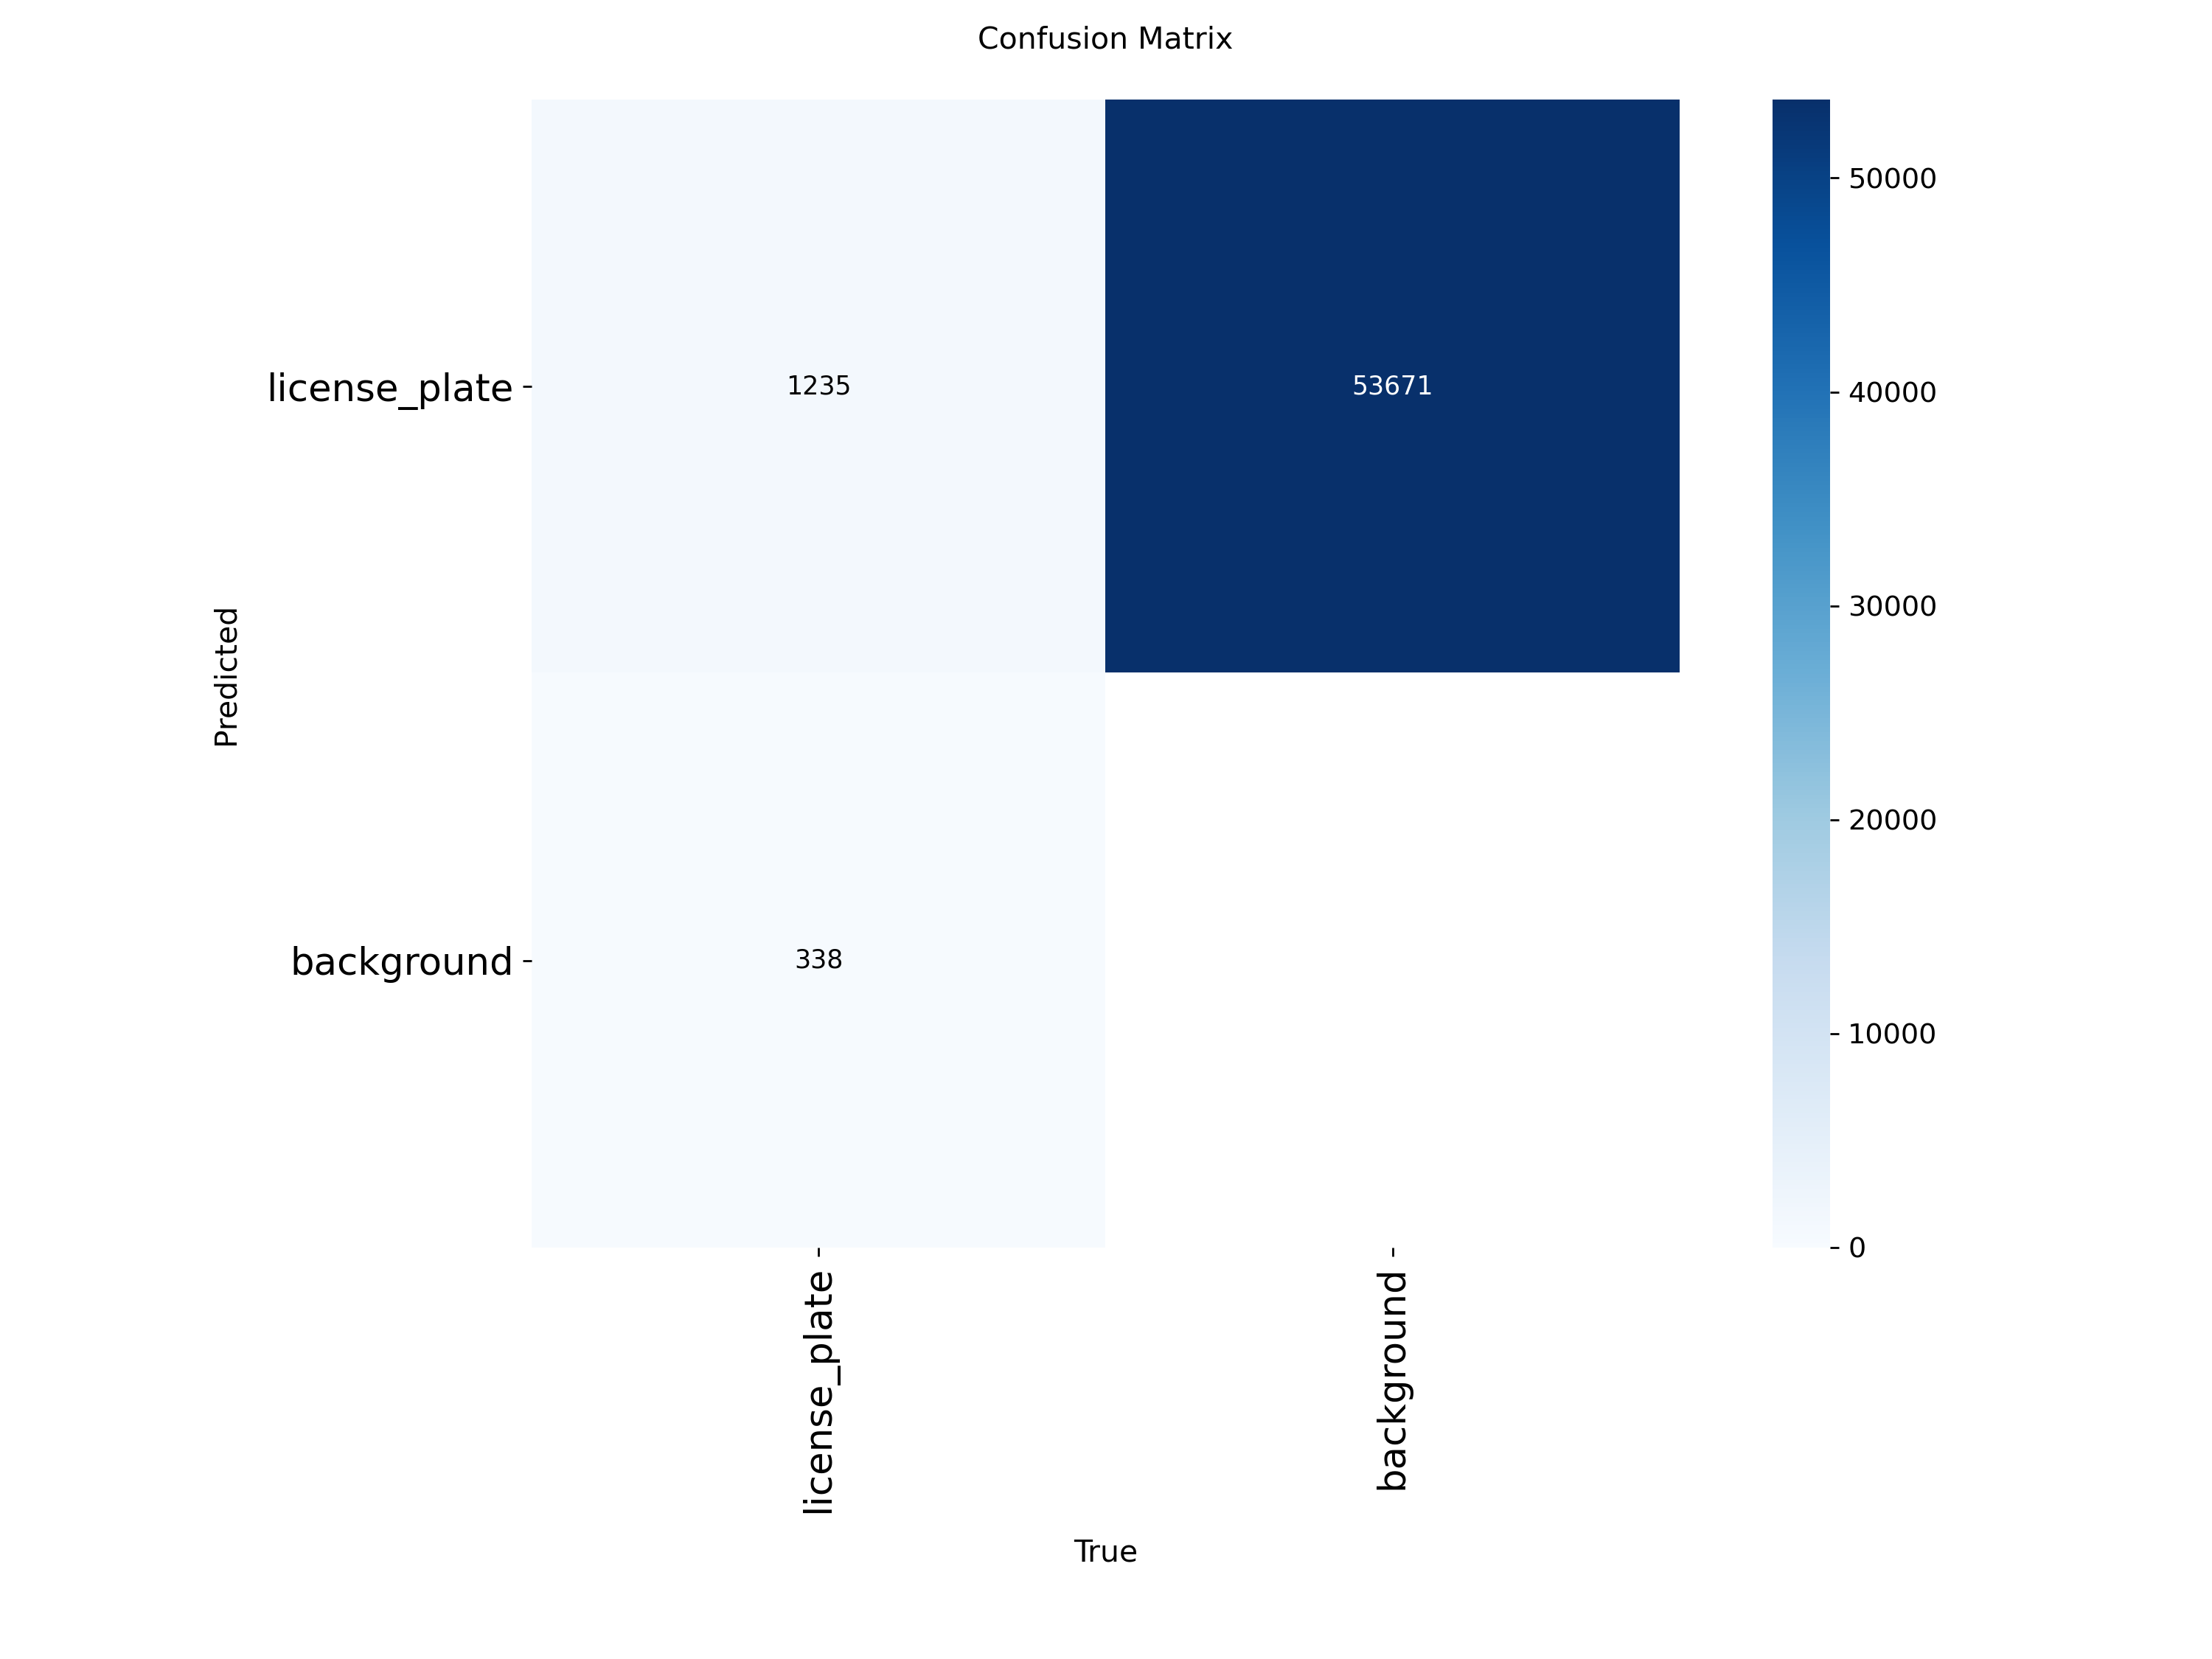

In [57]:
display(
    Image(
        filename="/content/runs/detect/train-3/confusion_matrix.png"
    )
)

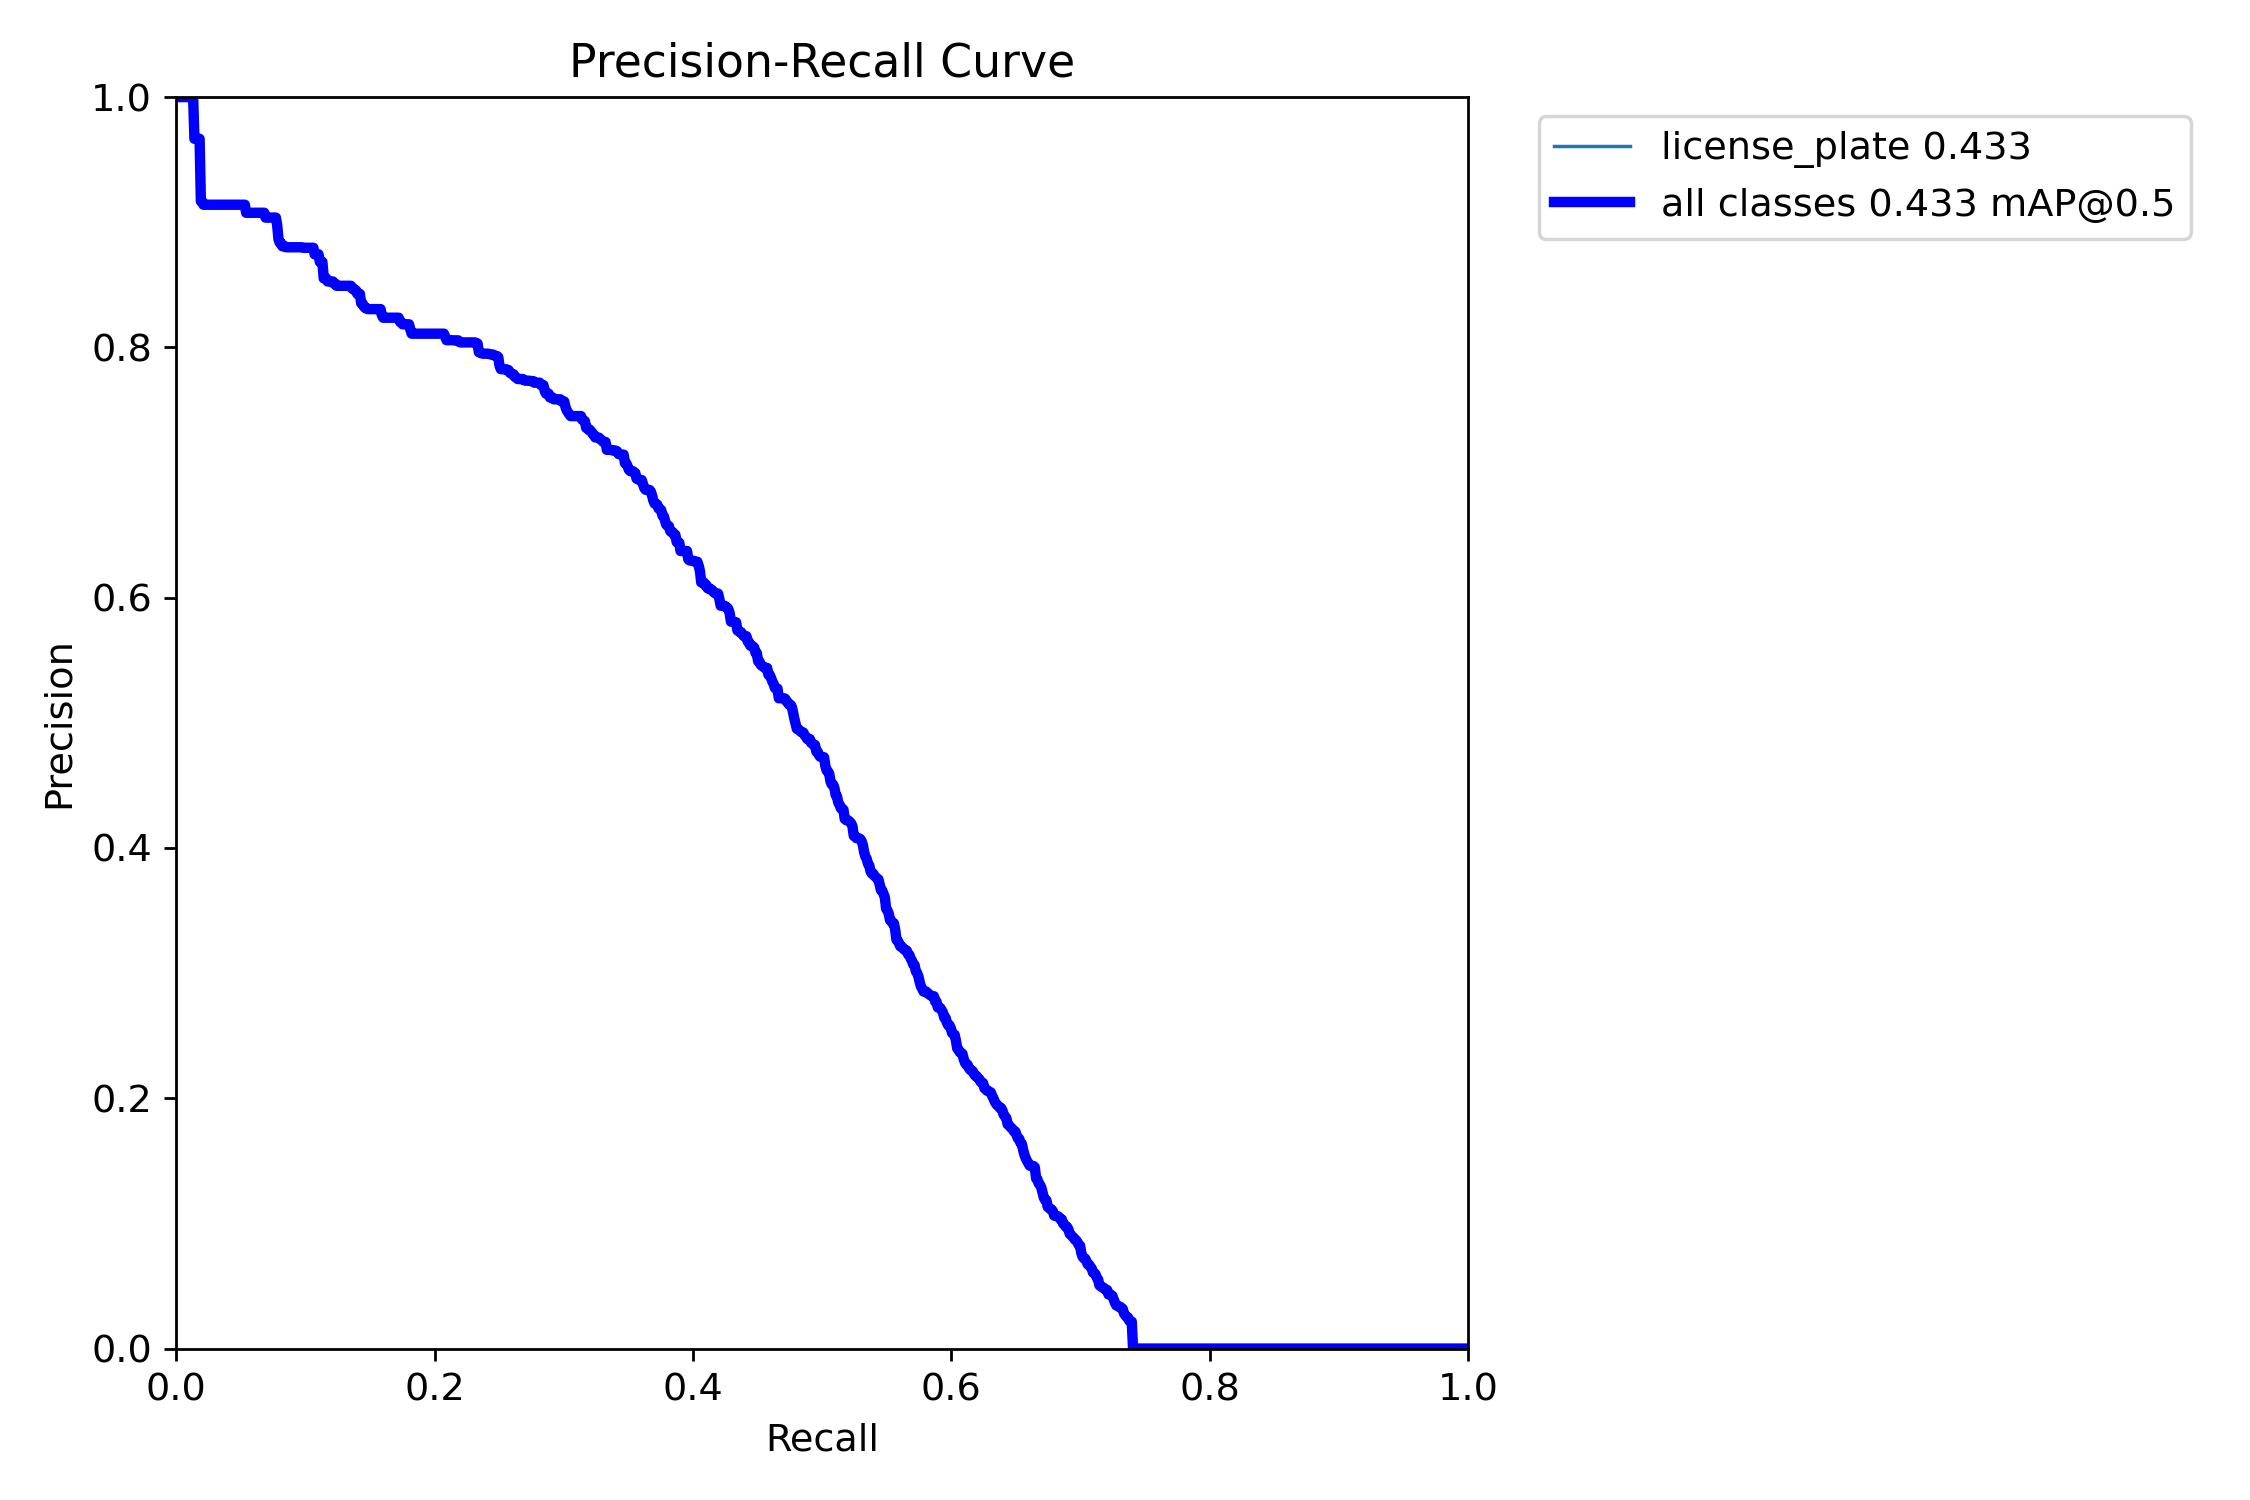

In [61]:
display(
    Image(
        filename="/content/runs/detect/train-3/BoxPR_curve.png"
    )
)

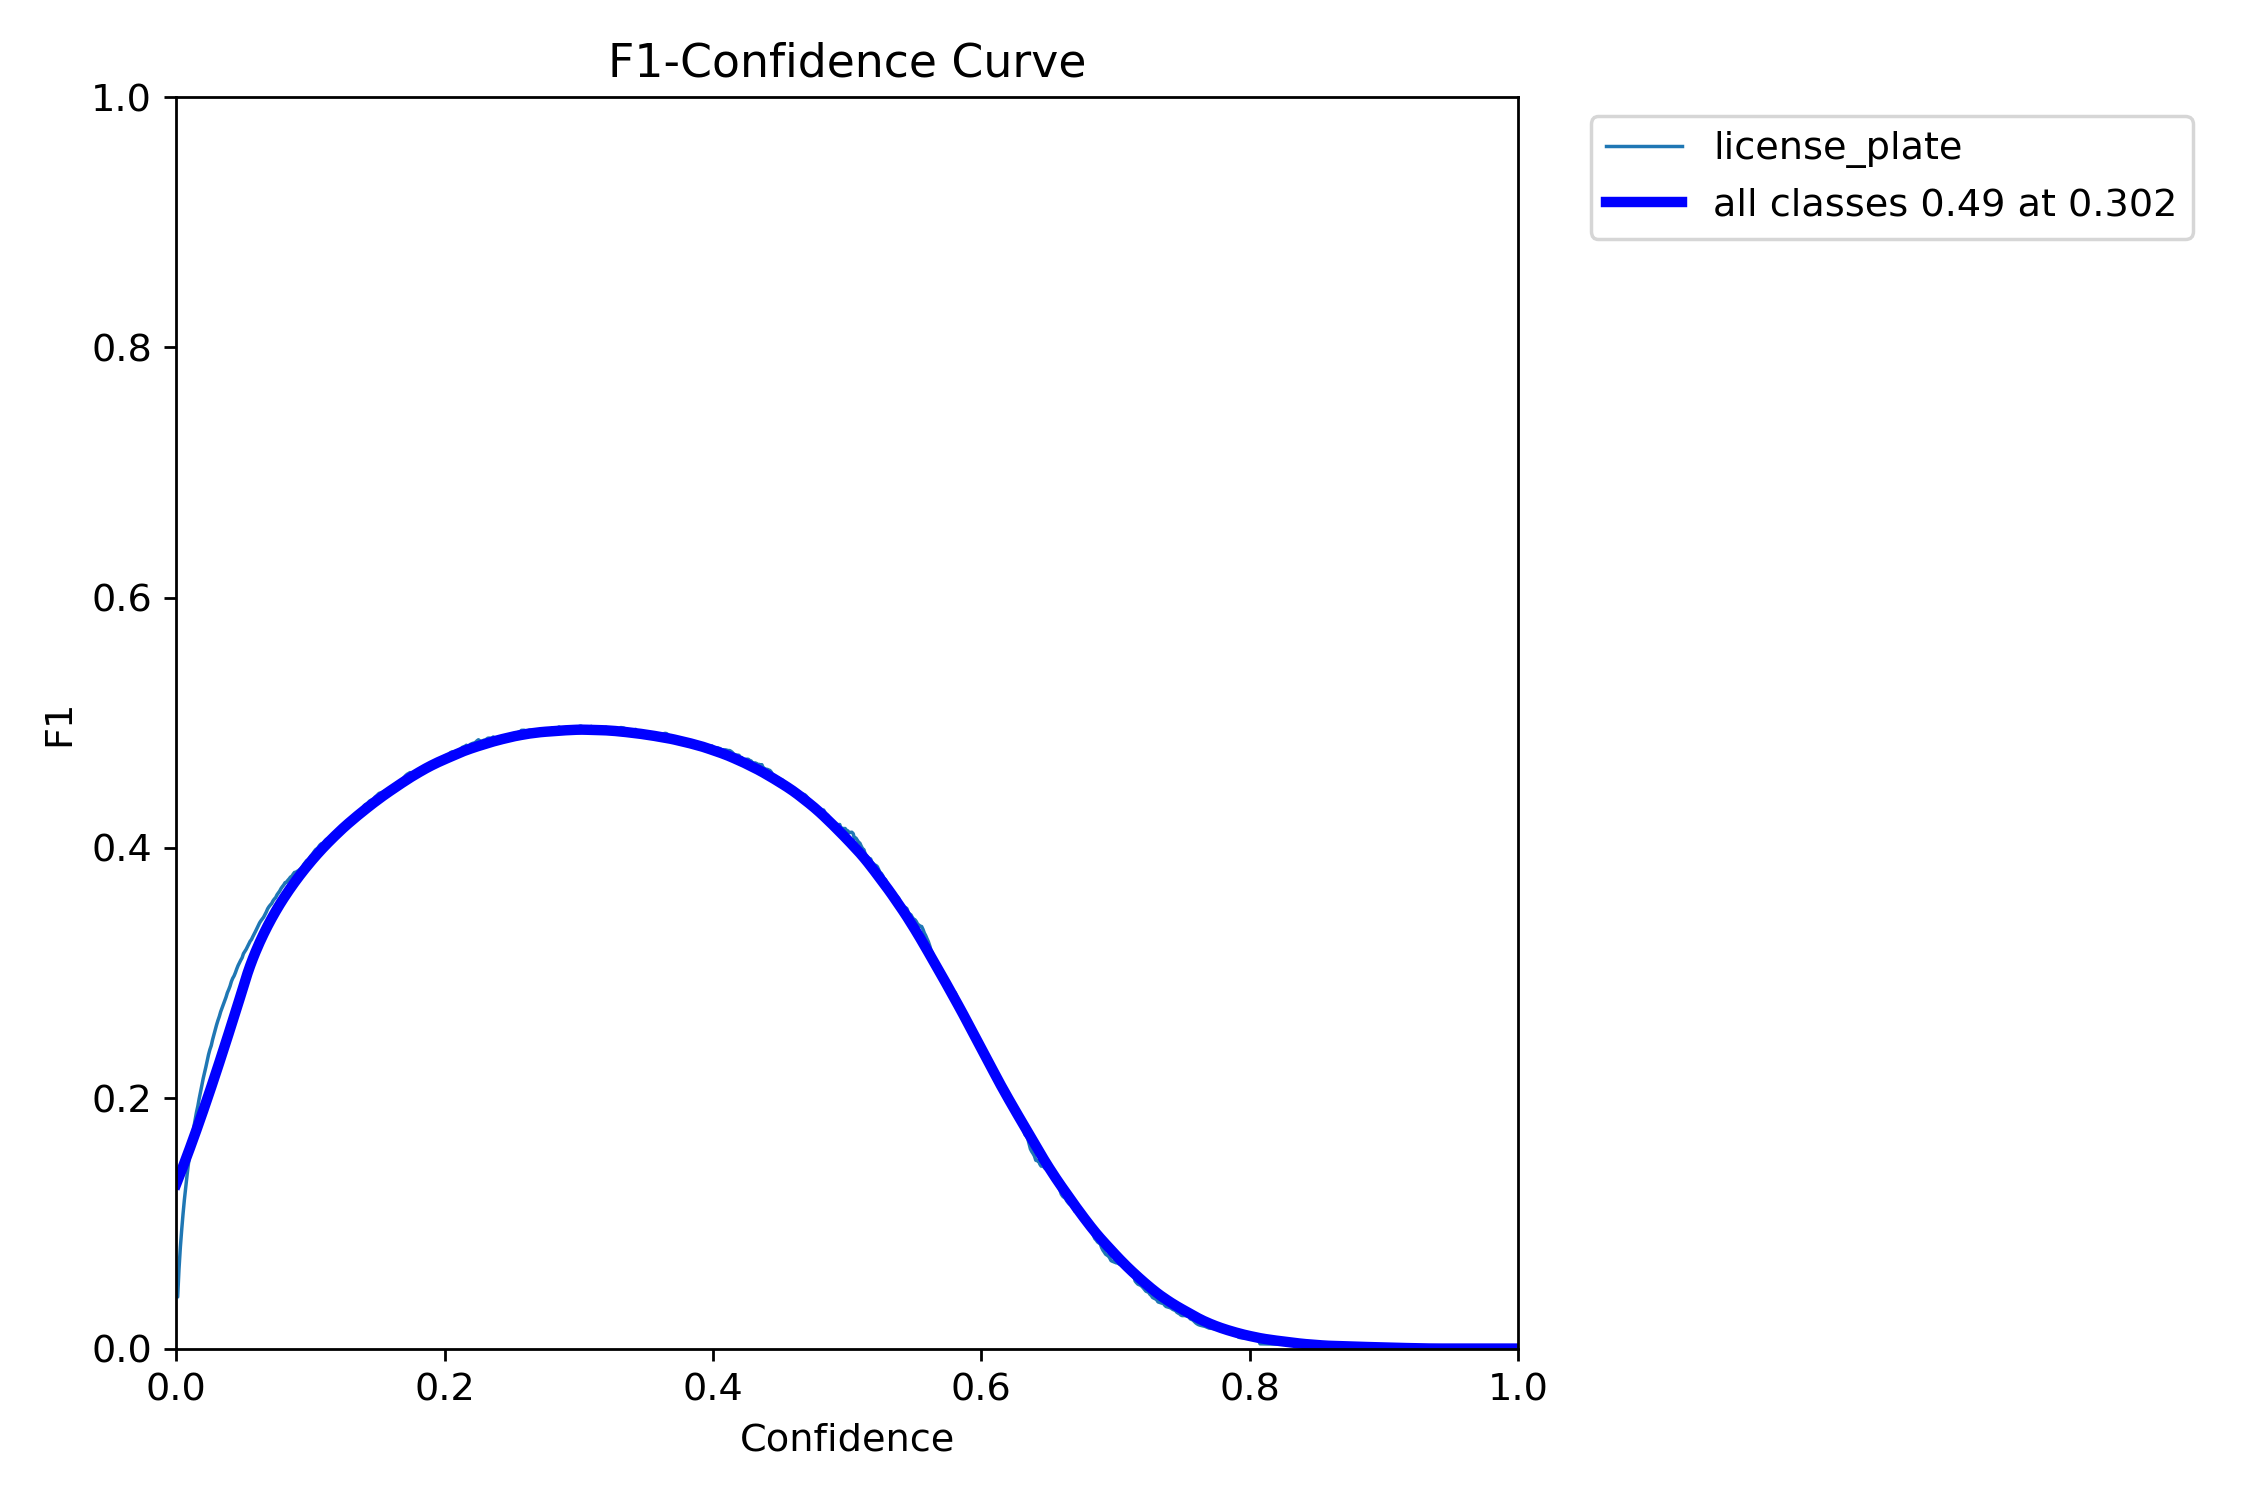

In [62]:
display(
    Image(
        filename="/content/runs/detect/train-3/BoxF1_curve.png"
    )
)

## Business Questions and Answers

### 1. How do you convert normalized YOLO bounding box coordinates into pixel coordinates?

YOLO annotations store bounding boxes in normalized format as `(center_x, center_y, width, height)`, where all values range from 0 to 1.

To convert them into pixel coordinates, the normalized values are multiplied by the image width and height. The top-left and bottom-right coordinates are then calculated as:

- `x1 = center_x × image_width − box_width × image_width / 2`
- `y1 = center_y × image_height − box_height × image_height / 2`
- `x2 = center_x × image_width + box_width × image_width / 2`
- `y2 = center_y × image_height + box_height × image_height / 2`

The resulting `(x1, y1, x2, y2)` coordinates are integer pixel positions that can be used by OpenCV to draw rectangles.

### 2. Write a function to overlay bounding boxes onto raw images. Why is this critical before training?

The `yolo_to_pixel_coords()` function converts normalized annotations into pixel coordinates, and OpenCV's `rectangle()` function is then used to draw the bounding boxes.

Visualizing the annotations before training is critical because it verifies that the image and label files are correctly matched and that the bounding boxes actually surround the license plates. Incorrect annotations would teach the model to detect the wrong regions and reduce final detection accuracy.

### 3. How did annotation quality impact the final blurring accuracy?

Annotation quality directly affects detection quality. Accurate and tightly positioned license-plate annotations help YOLOv8 learn the correct visual features and boundaries of plates.

The annotation visualization showed that the bounding boxes were correctly aligned with the license plates. This is important for privacy because inaccurate or oversized boxes could blur unnecessary parts of the image, while inaccurate or missing boxes could leave sensitive plate information visible.

### 4. How did you preprocess images before feeding them into YOLOv8 without losing fine-grained plate details?

Images were resized to `416 × 416` pixels during training and inference. This provided a balance between computational efficiency and preservation of useful visual details.

YOLOv8's training pipeline also applies standard augmentation and preprocessing techniques. Because license plates are relatively small objects, preserving sufficient image resolution is important for detecting their fine-grained features.

### 5. Why did you choose YOLOv8 instead of a two-stage detector?

YOLOv8 was selected because license-plate detection requires fast object detection and the eventual application is intended for traffic monitoring and privacy protection.

YOLOv8 performs detection in a single-stage pipeline, making it more suitable for real-time or near-real-time applications than traditional two-stage approaches such as Faster R-CNN, which generally require more computational processing.

### 6. Which YOLOv8 variant did you select, and how did it balance speed and accuracy?

The selected model was **YOLOv8s (small)**.

YOLOv8s provides a practical balance between model complexity, inference speed and detection accuracy. A larger model could potentially provide better accuracy but would require more computational resources and longer training and inference times.

The model was trained for 3 epochs at an image size of 416 pixels as a CPU-constrained baseline.

### 7. How did license plate characteristics influence your choice of model scale?

License plates are relatively small objects within larger vehicle images. Therefore, the model needs sufficient feature-extraction capability to identify small rectangular objects while still remaining computationally efficient.

YOLOv8s was selected as a compromise between detection capability and computational cost. The model is more capable than an extremely lightweight model while remaining practical for the available CPU environment.

### 8. How did you apply blurring only within the detected bounding box?

After YOLOv8 detects a license plate, the predicted bounding-box coordinates are extracted.

The corresponding image region is cropped and Gaussian blur is applied only to that region using OpenCV. The blurred region is then placed back into the original image.

This ensures that only the detected license plate is blurred while the rest of the image remains unchanged.

### Model Performance

The trained YOLOv8s baseline achieved the following validation results:

| Metric | Score |
|---|---:|
| Precision | 0.562 |
| Recall | 0.444 |
| mAP@50 | 0.432 |
| mAP@50-95 | 0.174 |

The model successfully detected license plates in sample images and the final privacy-preservation pipeline successfully blurred the detected license plates while keeping the remaining image visible.

### EDA Findings

The validation dataset contains **1,073 images** and **1,573 license-plate annotations**, giving an average of approximately **1.47 license plates per image**.

The bounding-box analysis shows that license plates generally occupy a relatively small region of the complete image. This confirms that the problem is a small-object detection task and highlights the importance of preserving image details during preprocessing.

### Business Impact

The proposed system can automatically identify license plates and blur them before images are used for monitoring, analytics or storage. This reduces the exposure of sensitive vehicle information while preserving the broader visual context needed for traffic analysis.

### Limitations and Future Improvements

The current model is a baseline trained on **1,493 sampled training images** because of the available CPU computational resources, rather than the complete 25,625-image training set.

For production deployment, the model should be retrained using the complete training dataset with more epochs and suitable hardware. Additional improvements could include confidence-threshold tuning, stronger augmentation, improved small-object detection settings and evaluation on a completely unseen test set.

## Business Insights and Recommendations

### Key Insights

1. **License plates are small objects within vehicle images.**
   The EDA showed an average of 1.47 license plates per validation image, while the bounding-box distribution confirmed that many plates occupy a relatively small portion of the image.

2. **Accurate annotations are essential for privacy protection.**
   Correct bounding boxes are necessary not only for good model training but also for ensuring that the actual license plate is blurred during deployment.

3. **YOLOv8s provides a practical baseline.**
   The selected YOLOv8s model achieved a validation Precision of 0.562, Recall of 0.444 and mAP@50 of 0.432. This demonstrates that the model learned to identify license plates, while also showing that further optimization is possible.

4. **The system successfully performs targeted privacy protection.**
   Instead of blurring the complete image, the system identifies the detected license-plate region and applies Gaussian blur only to that region. This preserves useful information such as vehicles, roads and surroundings.

5. **False negatives are particularly important in this application.**
   Since the purpose of the system is privacy preservation, a missed license plate could leave sensitive information visible. Therefore, improving recall should be an important priority for a production system.

### Recommendations

* Train the model using the complete 25,625-image training dataset.
* Increase the number of training epochs using suitable GPU resources.
* Tune the confidence threshold to improve the balance between missed plates and unnecessary detections.
* Use additional augmentation and small-object detection techniques where appropriate.
* Evaluate the final model on the separate 386-image test set.
* Monitor false-negative cases because missed detections represent a direct privacy risk.
* Consider integrating the model into a real-time traffic-camera pipeline for automatic privacy-preserving image processing.

### Overall Conclusion

The project demonstrates an end-to-end license-plate privacy pipeline using YOLOv8. The workflow covers dataset analysis, annotation validation, coordinate conversion, model training, evaluation, license-plate detection and targeted image blurring.

The baseline results demonstrate that YOLOv8 can learn the license-plate detection task, while the successful before-and-after visualization confirms that detected license plates can be selectively blurred. With training on the complete dataset and further model optimization, the system can be improved for more reliable real-world privacy protection.


## Final Project Summary

This project developed an automated license-plate detection and privacy-preservation pipeline using YOLOv8.

The dataset contains 25,625 training images, 1,073 validation images and 386 test images. Exploratory analysis showed 1,573 license-plate annotations in the validation set, with an average of 1.47 plates per image.

The project validated the YOLO annotation format by converting normalized coordinates into pixel coordinates and visually checking the ground-truth bounding boxes. A YOLOv8s model was then trained as a computationally efficient baseline using 1,493 sampled training images.

The model achieved a validation Precision of 0.562, Recall of 0.444, mAP@50 of 0.432 and mAP@50-95 of 0.174.

Finally, the detected license-plate regions were processed using Gaussian blur so that sensitive plate information was obscured while the remaining image content was preserved.

Overall, the project demonstrates how object detection and image processing can be combined to support automated privacy protection in traffic monitoring and surveillance systems.
